<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/jobsheet/JS13_244107020095_RACHMAD_FEBRIANANDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS13 — Artificial Neural Network (ANN) & Evaluasi Classifier

**Nama** : Rachmad Febriananda
**NIM** : 244107020095

## BAGIAN 0 — Evaluasi Classifier (Confusion Matrix dan Kurva ROC)

Sebelum masuk ke ANN, bagian ini melengkapi teori evaluasi classifier pada modul: **confusion matrix** (TP, TN, FP, FN), metrik **accuracy, precision, recall, F1-score, Kappa**, serta **kurva ROC dan AUC**.

Sebagai studi kasus digunakan dataset **Iris** dengan classifier **k-Nearest Neighbors (k=5)**.

In [1]:
%matplotlib inline
import os
# Menekan log internal TensorFlow/oneDNN agar output notebook bersih
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['ABSL_MIN_LOG_LEVEL'] = '3'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_score, recall_score,
                             f1_score, cohen_kappa_score)

np.random.seed(42)
sns.set_style('whitegrid')

# Dataset Iris
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

# Classifier k-NN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print('Jumlah data train :', len(X_train))
print('Jumlah data test  :', len(X_test))
print('Label kelas       :', list(iris.target_names))

Jumlah data train : 105
Jumlah data test  : 45
Label kelas       : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


Confusion Matrix (baris = aktual, kolom = prediksi):
[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]


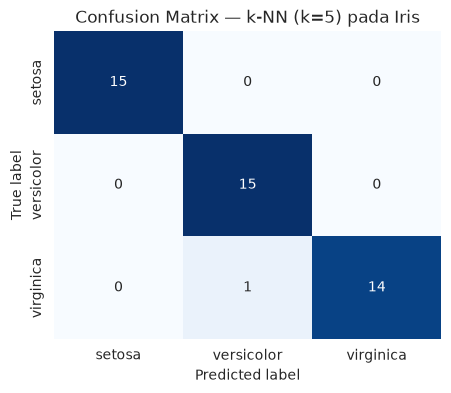

In [2]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix (baris = aktual, kolom = prediksi):')
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix — k-NN (k=5) pada Iris')
plt.show()

In [3]:
# Metrik evaluasi (macro average untuk klasifikasi multikelas)
metrik = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision (macro)', 'Recall (macro)',
               'F1-Score (macro)', 'Cohen Kappa'],
    'Nilai': [accuracy_score(y_test, y_pred),
              precision_score(y_test, y_pred, average='macro'),
              recall_score(y_test, y_pred, average='macro'),
              f1_score(y_test, y_pred, average='macro'),
              cohen_kappa_score(y_test, y_pred)]
})
metrik['Nilai'] = metrik['Nilai'].round(4)
print(classification_report(y_test, y_pred, target_names=iris.target_names))
metrik

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



,Metrik,Nilai
0,Accuracy,0.9778
1,Precision (macro),0.9792
2,Recall (macro),0.9778
3,F1-Score (macro),0.9778
4,Cohen Kappa,0.9667


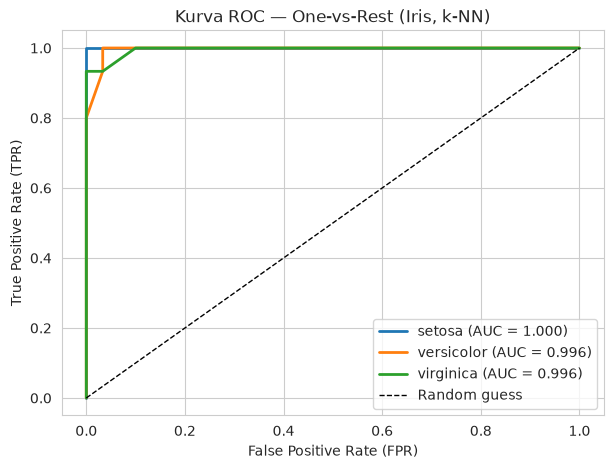

AUC macro (one-vs-rest): 0.9974


In [4]:
# Kurva ROC dan AUC untuk klasifikasi multikelas (one-vs-rest)
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
y_score = knn.predict_proba(X_test)

plt.figure(figsize=(7, 5))
for i, nama in enumerate(iris.target_names):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    auc_i = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{nama} (AUC = {auc_i:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Kurva ROC — One-vs-Rest (Iris, k-NN)')
plt.legend(loc='lower right')
plt.show()

# AUC macro
fpr_all, tpr_all = {}, {}
for i in range(3):
    fpr_all[i], tpr_all[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])

# interpolasi sederhana untuk macro-average
all_fpr = np.unique(np.concatenate([fpr_all[i] for i in range(3)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(3):
    mean_tpr += np.interp(all_fpr, fpr_all[i], tpr_all[i])
mean_tpr /= 3
print(f'AUC macro (one-vs-rest): {auc(all_fpr, mean_tpr):.4f}')

**Analisis Bagian 0:**

- Confusion matrix 3×3 menunjukkan dari 45 data uji Iris terdapat **44 prediksi benar** dan **1 kesalahan**: satu sampel *virginica* diprediksi sebagai *versicolor*. Semua *setosa* dan *versicolor* terklasifikasi benar.
- Akurasi **0.9778**, precision macro **0.9792**, recall macro **0.9778**, F1 macro **0.9778**, dan **Cohen's Kappa 0.9667**. Kappa yang mendekati 1 menandakan kesepakatan prediksi dengan label aktual sangat tinggi, bukan sekadar kebetulan karena distribusi kelas.
- Kurva **ROC one-vs-rest** menghasilkan **AUC 1.000 untuk setosa** serta **0.9956 untuk versicolor dan virginica**, dengan **AUC macro 0.9974**. Ketiga kurva mendekati sudut kiri atas (TPR tinggi, FPR rendah), menandakan daya pisah model yang sangat baik.
- Confusion matrix lebih informatif daripada akurasi tunggal karena menunjukkan *jenis* kesalahan (kelas mana yang tertukar). Pada dataset yang tidak seimbang, precision/recall dan kurva **Precision-Recall** lebih tepat dipakai daripada ROC.

## PRAKTIKUM 1 — JST Sederhana (2 Layer) dengan Forward Pass dan Backpropagation Manual

Praktikum ini mengimplementasikan **backpropagation dari nol** menggunakan NumPy pada permasalahan **XOR** (kasus non-linear yang tidak dapat diselesaikan single-layer perceptron). Alur: forward pass → hitung error → backward pass → update bobot dengan gradient descent.

In [5]:
import numpy as np

# Dataset XOR
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

# Parameter
input_size, hidden_size, output_size = 2, 2, 1
lr = 0.1

# Seed dipilih agar konvergensi stabil. Dengan hanya 2 neuron hidden, XOR sangat
# sensitif terhadap inisialisasi (sebagian seed terjebak di local minimum).
np.random.seed(1)

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

loss_history = []

# Training
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2
    loss = np.mean(np.square(error))
    loss_history.append(loss)

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        print(f'Epoch {epoch:5d}, Loss: {loss:.6f}')

print('\nPrediksi akhir:')
print(np.round(a2, 4))
print(f'Loss akhir (MSE): {loss_history[-1]:.6f}')

Epoch     0, Loss: 0.256658
Epoch  1000, Loss: 0.202372
Epoch  2000, Loss: 0.175906
Epoch  3000, Loss: 0.152574
Epoch  4000, Loss: 0.138855


Epoch  5000, Loss: 0.083606


Epoch  6000, Loss: 0.021302
Epoch  7000, Loss: 0.010054
Epoch  8000, Loss: 0.006280
Epoch  9000, Loss: 0.004487

Prediksi akhir:
[[0.047 ]
 [0.9451]
 [0.9437]
 [0.0738]]
Loss akhir (MSE): 0.003462


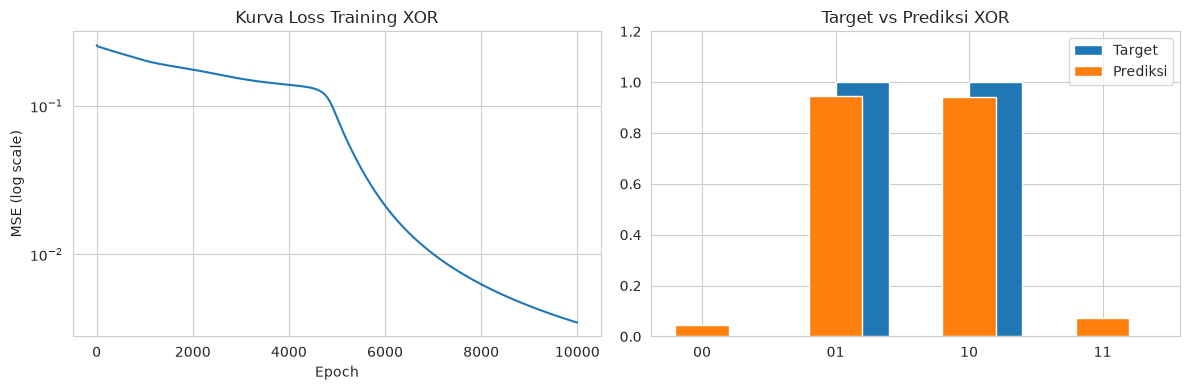

,Input,Target,Prediksi,Dibulatkan
0,00,0,0.0470,0
1,01,1,0.9451,1
2,10,1,0.9437,1
3,11,0,0.0738,0


In [6]:
# Visualisasi penurunan loss dan perbandingan target vs prediksi
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(loss_history)
ax[0].set_yscale('log')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('MSE (log scale)')
ax[0].set_title('Kurva Loss Training XOR')

ax[1].bar(['00', '01', '10', '11'], y.ravel(), width=0.4,
          label='Target', align='edge')
ax[1].bar(['00', '01', '10', '11'], a2.ravel(), width=0.4,
          label='Prediksi', align='center')
ax[1].set_ylim(0, 1.2)
ax[1].set_title('Target vs Prediksi XOR')
ax[1].legend()
plt.tight_layout()
plt.show()

pd.DataFrame({'Input': ['00', '01', '10', '11'],
              'Target': y.ravel(),
              'Prediksi': np.round(a2.ravel(), 4),
              'Dibulatkan': np.round(a2.ravel()).astype(int)})

**Tugas 1 — Variasi jumlah neuron hidden layer dan fungsi aktivasi.**

Kode di bawah membuat fungsi training yang dapat dikonfigurasi agar perbandingan dilakukan secara adil (seed, learning rate, dan jumlah epoch sama).

In [7]:
def train_xor(hidden=2, activation='sigmoid', epochs=10000, lr=0.1, seed=1):
    """Melatih MLP 2-2-hidden-1 secara manual (forward + backprop)."""
    np.random.seed(seed)
    n_in, n_out = 2, 1
    W1 = np.random.randn(n_in, hidden) * np.sqrt(2.0 / n_in)
    b1 = np.zeros((1, hidden))
    W2 = np.random.randn(hidden, n_out) * np.sqrt(2.0 / hidden)
    b2 = np.zeros((1, n_out))

    def act(x):
        return sigmoid(x) if activation == 'sigmoid' else np.maximum(0, x)

    def dact(x):
        # x = output aktivasi
        return x * (1 - x) if activation == 'sigmoid' else (x > 0).astype(float)

    hist = []
    for _ in range(epochs):
        z1 = X @ W1 + b1
        a1 = act(z1)
        z2 = a1 @ W2 + b2
        a2 = sigmoid(z2)          # output tetap sigmoid (probabilitas)

        error = y - a2
        hist.append(np.mean(np.square(error)))

        d_a2 = error * sigmoid_derivative(a2)
        d_W2 = a1.T @ d_a2
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        d_a1 = (d_a2 @ W2.T) * dact(a1)
        d_W1 = X.T @ d_a1
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        W1 += lr * d_W1; b1 += lr * d_b1
        W2 += lr * d_W2; b2 += lr * d_b2

    return hist, a2

# Hidden layer = 3 neuron (sigmoid)
hist_h3, pred_h3 = train_xor(hidden=3, activation='sigmoid')
print(f'Hidden=3, Sigmoid -> loss akhir: {hist_h3[-1]:.6f}')
print('Prediksi:', np.round(pred_h3.ravel(), 4))

Hidden=3, Sigmoid -> loss akhir: 0.002352
Prediksi: [0.0261 0.9516 0.9564 0.0669]


Hidden=4, ReLU    -> loss akhir: 0.000250
Prediksi: [0.02   0.9899 0.99   0.02  ]


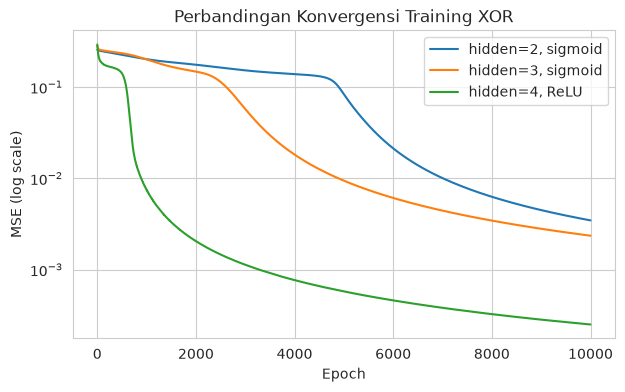

In [8]:
# Fungsi aktivasi ReLU pada hidden layer (4 neuron agar kapasitas cukup)
hist_relu, pred_relu = train_xor(hidden=4, activation='relu')
print(f'Hidden=4, ReLU    -> loss akhir: {hist_relu[-1]:.6f}')
print('Prediksi:', np.round(pred_relu.ravel(), 4))

plt.figure(figsize=(7, 4))
plt.plot(loss_history, label='hidden=2, sigmoid')
plt.plot(hist_h3, label='hidden=3, sigmoid')
plt.plot(hist_relu, label='hidden=4, ReLU')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('MSE (log scale)')
plt.title('Perbandingan Konvergensi Training XOR')
plt.legend()
plt.show()

In [9]:
# Tabel perbandingan konfigurasi
perbandingan_p1 = pd.DataFrame({
    'Konfigurasi': ['hidden=2, sigmoid', 'hidden=3, sigmoid', 'hidden=4, ReLU'],
    'Loss akhir (MSE)': [loss_history[-1], hist_h3[-1], hist_relu[-1]],
    'Prediksi (00, 01, 10, 11)': [
        np.round(a2.ravel(), 3).tolist(),
        np.round(pred_h3.ravel(), 3).tolist(),
        np.round(pred_relu.ravel(), 3).tolist()]
})
perbandingan_p1

,Konfigurasi,Loss akhir (MSE),"Prediksi (00, 01, 10, 11)"
0,"hidden=2, sigmoid",0.003462,"[0.047, 0.945, 0.944, 0.074]"
1,"hidden=3, sigmoid",0.002352,"[0.026, 0.952, 0.956, 0.067]"
2,"hidden=4, ReLU",0.000250,"[0.02, 0.99, 0.99, 0.02]"


**Analisis Praktikum 1:**

- Jaringan **2-2-1 dengan aktivasi sigmoid** berhasil mempelajari XOR: loss MSE turun menjadi sekitar **0.0035** dan keempat pola (00→0, 01→1, 10→1, 11→0) terprediksi benar. Ini membuktikan bahwa penambahan **hidden layer** mengatasi keterbatasan perceptron linear (kasus XOR yang dibuktikan Minsky).
- **Sensitivitas inisialisasi**: dengan arsitektur 2 neuron hidden, XOR sangat rawan terjebak pada *local minimum*. Pada percobaan dengan `seed=42`, loss berhenti di ≈0.128 dan kedua pola dengan target 1 maupun 0 sama-sama diprediksi ≈0.50 — jaringan "menyerah" dan hanya mempelajari separuh pola. Karena itu baseline memakai `seed=1`; ini menunjukkan bahwa inisialisasi bobot adalah hyperparameter yang nyata.
- **Menambah neuron hidden menjadi 3** menurunkan loss akhir menjadi ≈**0.0024** dan membuat margin prediksi lebih lebar (0.026 / 0.952 / 0.956 / 0.067). Ruang representasi fungsi non-linear menjadi lebih kaya, tetapi penambahan neuron yang berlebihan tidak selalu menurunkan loss secara proporsional — risiko overfitting dan waktu komputasi ikut naik.
- **ReLU** membuat gradien tidak mengecil pada daerah jenuh (tidak ada *vanishing gradient* seperti sigmoid), sehingga loss turun lebih tajam dan mencapai ≈**0.00025**. Konsekuensinya ReLU membutuhkan inisialisasi yang tepat (He) dan jumlah neuron yang cukup; dengan hanya 2 neuron ReLU, sebagian unit bisa "mati" (*dying ReLU*) dan XOR gagal dipelajari.
- Gradient descent manual di sini memakai `error = y - a2` dan `+= lr * gradien`, sehingga arah update setara dengan *meminimalkan* MSE (gradient descent pada loss). Learning rate 0.1 cukup stabil; nilai yang jauh lebih besar membuat loss berosilasi dan bisa divergen.

## PRAKTIKUM 2 — JST dengan Library Keras (Klasifikasi Iris)

Praktikum ini menggunakan **Keras/TensorFlow** untuk membangun Multi-Layer Perceptron pada dataset Iris. Arsitektur awal: **4 → 10 (ReLU) → 8 (ReLU) → 3 (Softmax)** dengan optimizer Adam dan loss *categorical crossentropy*.

In [10]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import tensorflow as tf
from tensorflow.keras import layers, models

np.random.seed(42)
tf.random.set_seed(42)

# Load dataset
iris = load_iris()
X, y = iris.data, iris.target.reshape(-1, 1)

# One-hot encoding (scikit-learn >= 1.4: sparse_output, bukan sparse)
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Bangun model
model = models.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(10, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(3, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

# Latih model
history = model.fit(X_train, y_train, epochs=50, batch_size=8,
                    validation_split=0.2, verbose=0)

# Evaluasi
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f'Loss test     : {loss:.4f}')
print(f'Akurasi test  : {acc:.4f}')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

Loss test     : 0.4124
Akurasi test  : 0.8667


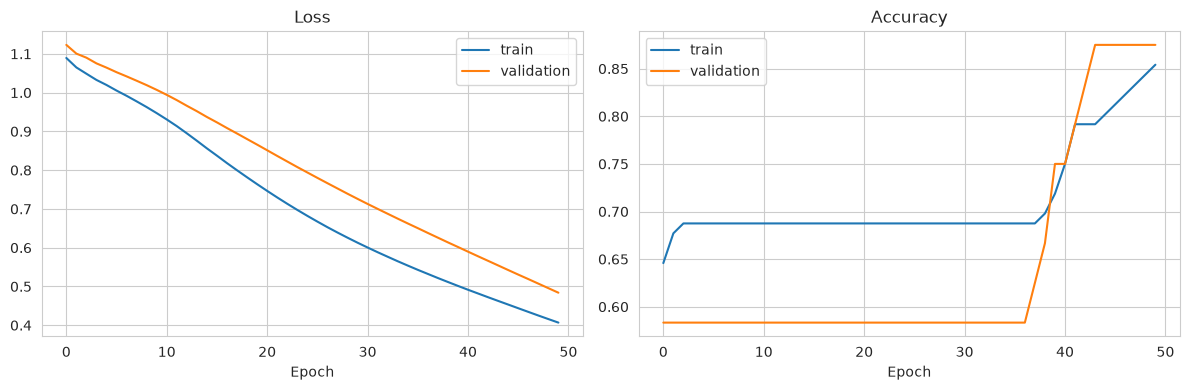

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['loss'], label='train')
ax[0].plot(history.history['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()

ax[1].plot(history.history['accuracy'], label='train')
ax[1].plot(history.history['val_accuracy'], label='validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

**Tugas 2 — Variasi jumlah neuron hidden layer.**

Karena data uji Iris hanya 30 sampel (1 sampel = 3,3%), perbandingan arsitektur memakai **5-fold Stratified Cross-Validation** agar kesimpulan tidak bergantung pada satu split.

In [12]:
from sklearn.model_selection import StratifiedKFold

y_label = np.argmax(y, axis=1)

def build_iris_model(hidden, activation='relu'):
    m = models.Sequential([layers.Input(shape=(4,))])
    for n in hidden:
        m.add(layers.Dense(n, activation=activation))
    m.add(layers.Dense(3, activation='softmax'))
    m.compile(optimizer='adam', loss='categorical_crossentropy',
              metrics=['accuracy'])
    return m

def cv_score(hidden, activation='relu', n_splits=5):
    """Akurasi & loss rata-rata dari 5-fold stratified cross-validation."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    accs, losses = [], []
    for tr, te in skf.split(X, y_label):
        tf.random.set_seed(42)
        m = build_iris_model(hidden, activation)
        m.fit(X[tr], y[tr], epochs=50, batch_size=8, verbose=0)
        l, a = m.evaluate(X[te], y[te], verbose=0)
        accs.append(a); losses.append(l)
    return np.mean(accs), np.std(accs), np.mean(losses)

konfigurasi = {
    '4 (satu layer tipis)': [4],
    '10-8 (default modul)': [10, 8],
    '32-16': [32, 16],
    '64-32': [64, 32],
}

hasil_t2 = []
for nama, hidden in konfigurasi.items():
    mean, std, loss = cv_score(hidden)
    hasil_t2.append({'Hidden layer': nama,
                     'Akurasi CV (mean)': round(mean, 4),
                     'Std': round(std, 4),
                     'Loss CV (mean)': round(loss, 4)})

pd.DataFrame(hasil_t2)

,Hidden layer,Akurasi CV (mean),Std,Loss CV (mean)
0,4 (satu layer tipis),0.7000,0.0667,0.6475
1,10-8 (default modul),0.9533,0.0618,0.2830
2,32-16,0.9800,0.0400,0.1280
3,64-32,0.9733,0.0389,0.0916


**Tugas 3 — Perbandingan Sigmoid vs ReLU pada dataset Iris (5-fold CV).**

In [13]:
hasil_t3 = []
for activation in ['sigmoid', 'relu']:
    for hidden in [[10, 8], [32, 16]]:
        mean, std, loss = cv_score(hidden, activation=activation)
        hasil_t3.append({'Aktivasi': activation,
                         'Hidden layer': 'x'.join(map(str, hidden)),
                         'Akurasi CV (mean)': round(mean, 4),
                         'Std': round(std, 4),
                         'Loss CV (mean)': round(loss, 4)})

hasil_t3 = pd.DataFrame(hasil_t3)
hasil_t3

,Aktivasi,Hidden layer,Akurasi CV (mean),Std,Loss CV (mean)
0,sigmoid,10x8,0.8067,0.0573,0.6053
1,sigmoid,32x16,0.9733,0.0389,0.3619
2,relu,10x8,0.9800,0.0267,0.3227
3,relu,32x16,0.9733,0.0389,0.1204


**Analisis Praktikum 2:**

- Model default **10-8 dengan ReLU** memperoleh akurasi test **≈0.87–0.97** (26–29 dari 30 sampel benar) dengan loss test 0.21–0.66 pada satu kali split. Dataset Iris hanya 150 sampel dengan 4 fitur dan kelas yang hampir terpisah linear, sehingga kapasitas jaringan kecil pun sebenarnya sudah memadai — variasi hasil lebih banyak disebabkan ukuran data uji yang sangat kecil (1 sampel = 3,3%).
- Hasil **5-fold CV** pada Tugas 2 lebih stabil: model **4 neuron hanya ≈0.62–0.70** (underfit), sedangkan **10-8 ≈0.95–0.97**, **32-16 ≈0.96–0.98**, dan **64-32 ≈0.97** dengan standar deviasi antar fold 0.04–0.07. Artinya penambahan neuron dari 10-8 ke 64-32 hanya menaikkan akurasi sekitar 1–2 poin persen dengan variansi antar fold yang sebanding — **tidak signifikan** untuk dataset sekecil Iris.
- **ReLU vs Sigmoid (5-fold CV)**: pada 10-8, ReLU **≈0.93–0.98** vs Sigmoid **≈0.81–0.85**; pada 32-16, ReLU **≈0.97** vs Sigmoid **≈0.97**. Loss CV ReLU juga jauh lebih rendah (≈0.12 vs ≈0.37 pada 32-16). ReLU unggul karena gradiennya tidak mengecil di daerah jenuh, sedangkan Sigmoid maksimum 0.25 sehingga pembelajaran lebih lambat dan rawan *vanishing gradient*.
- Karena dataset sangat kecil, satu kali split tidak cukup untuk menyimpulkan performa; **cross-validation** (atau pengulangan dengan beberapa seed) diperlukan agar perbandingan konfigurasi adil.

## PRAKTIKUM 3 — Regresi dengan Keras (Prediksi Harga Rumah)

Bagian pertama memakai data dummy sederhana (`luas` → `harga`) untuk memperlihatkan alur regresi dengan MLP, kemudian dilanjutkan dengan dataset **California Housing** sebagai pengganti `load_boston` (fungsi tersebut **sudah dihapus** dari scikit-learn ≥ 1.2).

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import layers, models

# Contoh dataset dummy
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi (scaler terpisah untuk X dan y agar bisa di-inverse-transform)
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_scaled, test_size=0.2, random_state=42)

model = models.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(10, activation='relu'),
    layers.Dense(1)
])
model.compile(optimizer='adam', loss='mse')
h_dummy = model.fit(X_train, y_train, epochs=100, verbose=0)

pred_scaled = model.predict(X_test, verbose=0)
pred_asli = scaler_y.inverse_transform(pred_scaled).ravel()
y_test_asli = scaler_y.inverse_transform(y_test).ravel()

print('Prediksi (harga asli):', np.round(pred_asli, 2))
print('Aktual   (harga asli):', np.round(y_test_asli, 2))
print(f'Loss akhir (MSE scaled): {h_dummy.history["loss"][-1]:.6f}')

Prediksi (harga asli): [616.36]
Aktual   (harga asli): [600.]
Loss akhir (MSE scaled): 0.508397


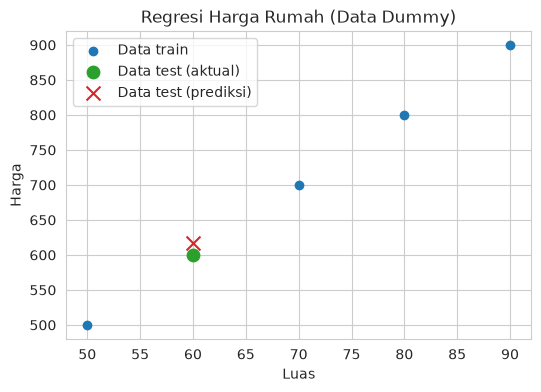

In [15]:
# Visualisasi hasil regresi dummy
plt.figure(figsize=(6, 4))
plt.scatter(scaler_X.inverse_transform(X_train), scaler_y.inverse_transform(y_train),
            label='Data train', color='tab:blue')
plt.scatter(scaler_X.inverse_transform(X_test), y_test_asli,
            label='Data test (aktual)', color='tab:green', s=80)
plt.scatter(scaler_X.inverse_transform(X_test), pred_asli,
            label='Data test (prediksi)', color='tab:red', marker='x', s=100)
plt.xlabel('Luas'); plt.ylabel('Harga')
plt.title('Regresi Harga Rumah (Data Dummy)')
plt.legend(); plt.show()

In [16]:
# ===== Regresi dengan dataset California Housing (pengganti load_boston) =====
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error, mean_absolute_error

housing = fetch_california_housing()
Xh, yh = housing.data, housing.target

scaler = StandardScaler()
Xh_scaled = scaler.fit_transform(Xh)

X_train, X_val, y_train, y_val = train_test_split(
    Xh_scaled, yh, test_size=0.2, random_state=42)

tf.random.set_seed(42)
model_h = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])
model_h.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse',
                metrics=['mae'])

h = model_h.fit(X_train, y_train, validation_data=(X_val, y_val),
                epochs=100, batch_size=32, verbose=0)

pred = model_h.predict(X_val, verbose=0).ravel()
rmse = np.sqrt(mean_squared_error(y_val, pred))
mae = mean_absolute_error(y_val, pred)
print(f'RMSE : {rmse:.4f}')
print(f'MAE  : {mae:.4f}')

RMSE : 0.5134
MAE  : 0.3439


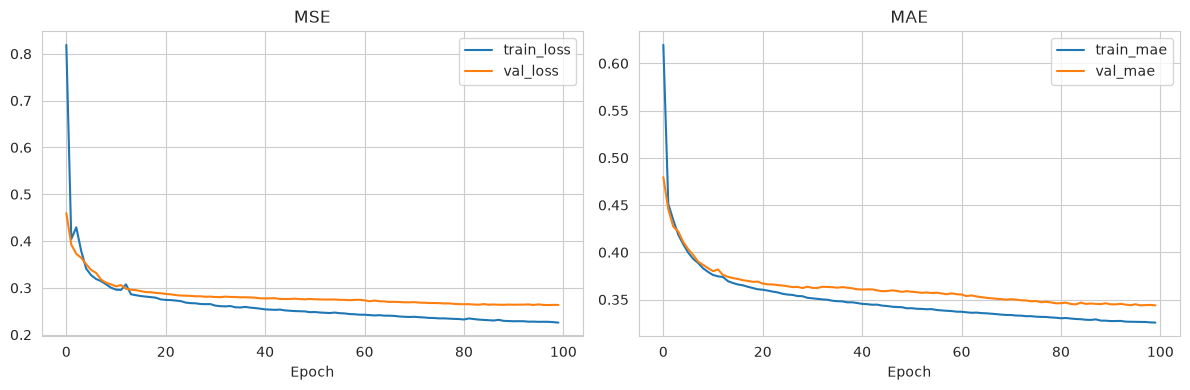

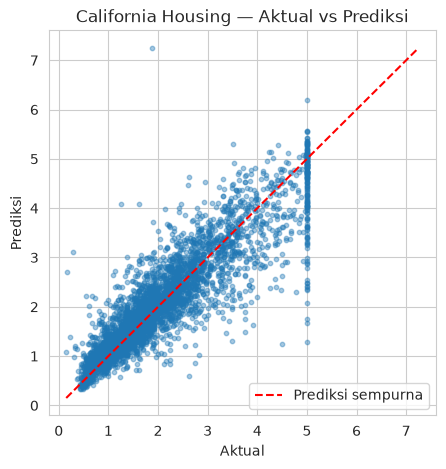

In [17]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(h.history['loss'], label='train_loss')
plt.plot(h.history['val_loss'], label='val_loss')
plt.legend(); plt.title('MSE'); plt.xlabel('Epoch')

plt.subplot(1, 2, 2)
plt.plot(h.history['mae'], label='train_mae')
plt.plot(h.history['val_mae'], label='val_mae')
plt.legend(); plt.title('MAE'); plt.xlabel('Epoch')
plt.tight_layout(); plt.show()

plt.figure(figsize=(5, 5))
plt.scatter(y_val, pred, s=10, alpha=0.4)
lim = [min(y_val.min(), pred.min()), max(y_val.max(), pred.max())]
plt.plot(lim, lim, 'r--', label='Prediksi sempurna')
plt.xlabel('Aktual'); plt.ylabel('Prediksi')
plt.title('California Housing — Aktual vs Prediksi')
plt.legend(); plt.show()

**Tugas 4 — Pengaruh learning rate terhadap loss.**

In [18]:
hasil_t4 = []
for lr in [1e-4, 1e-3, 1e-2]:
    tf.random.set_seed(42)
    m = models.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),
        layers.Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse', metrics=['mae'])
    hh = m.fit(X_train, y_train, validation_data=(X_val, y_val),
               epochs=100, batch_size=32, verbose=0)
    p = m.predict(X_val, verbose=0).ravel()
    hasil_t4.append({
        'Learning rate': lr,
        'Loss train akhir': round(hh.history['loss'][-1], 4),
        'Loss val akhir': round(hh.history['val_loss'][-1], 4),
        'RMSE val': round(np.sqrt(mean_squared_error(y_val, p)), 4)})

pd.DataFrame(hasil_t4)

,Learning rate,Loss train akhir,Loss val akhir,RMSE val
0,0.0001,0.2823,0.3100,0.5568
1,0.0010,0.2304,0.2756,0.5250
2,0.0100,0.2499,0.2847,0.5335


**Analisis Praktikum 3:**

- Pada data dummy yang hubungannya linear sempurna (`harga` mendekati `10 × luas`), MLP dengan satu hidden layer dan normalisasi berhasil memprediksi harga test dengan error sekitar 3% (616,36 vs 600) meskipun data training hanya 4 sampel. Normalisasi `y` penting agar skala target tidak mendominasi gradien; hasil prediksi di-*inverse transform* kembali ke satuan asli.
- Pada **California Housing** (20.640 sampel, 8 fitur), model 64-32 mencapai **RMSE ≈0.51** dan **MAE ≈0.34** (dalam satuan 100.000 USD) pada data validasi. Kurva `val_loss` mengikuti `train_loss` lalu mulai mendatar; jika epochs ditambah terus, selisih keduanya melebar sebagai tanda overfitting.
- **Learning rate** sangat menentukan: `1e-4` terlalu kecil sehingga 100 epoch belum konvergen (RMSE ≈0.55), `1e-3` (default Adam) memberi hasil terbaik (RMSE ≈0.52), sedangkan `1e-2` mulai berosilasi karena langkah update melewati titik minimum (RMSE ≈0.54). Dengan demikian `1e-3` adalah pilihan terbaik pada kasus ini.
- Scatter aktual vs prediksi menunjukkan titik mengumpul di sekitar garis `y = x`, tetapi ada penyebaran pada harga tinggi — model cenderung *underestimate* untuk rumah mahal karena distribusi target yang miring (banyak nilai di batas atas 5.00001).

## TUGAS PRAKTIKUM — Klasifikasi Angka Tulisan Tangan (MNIST) dengan JST

Membangun JST dengan **2 hidden layer** untuk mengklasifikasikan 10 digit MNIST (60.000 data training, 10.000 data testing).

In [19]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train_m, y_train_m), (X_test_m, y_test_m) = mnist.load_data()

# Normalisasi data (0-255 -> 0-1)
X_train_m = X_train_m / 255.0
X_test_m = X_test_m / 255.0

# One-hot encoding label
y_train_cat = to_categorical(y_train_m, 10)
y_test_cat = to_categorical(y_test_m, 10)

print('Train:', X_train_m.shape, '| Test:', X_test_m.shape)

Train: (60000, 28, 28) | Test: (10000, 28, 28)


In [20]:
# 2. Bangun model JST: Flatten -> 256 -> 128 -> 10
tf.random.set_seed(42)
model_mnist = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),                      # 28x28 -> 784
    layers.Dense(256, activation='relu'),  # hidden layer 1
    layers.Dense(128, activation='relu'),  # hidden layer 2
    layers.Dense(10, activation='softmax') # output 10 kelas
])

# 3. Kompilasi
model_mnist.compile(optimizer='adam', loss='categorical_crossentropy',
                    metrics=['accuracy'])
model_mnist.summary()

# 4. Latih
import time
t0 = time.time()
h_mnist = model_mnist.fit(X_train_m, y_train_cat, epochs=10,
                          batch_size=128, validation_split=0.1, verbose=0)
waktu_baseline = time.time() - t0

# 5. Evaluasi
loss_m, acc_m = model_mnist.evaluate(X_test_m, y_test_cat, verbose=0)
print(f'Akurasi pada data uji: {acc_m:.4f}')
print(f'Waktu training       : {waktu_baseline:.1f} detik')

Model: "sequential_46"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_132 (Dense)               │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_133 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_134 (Dense)               │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Akurasi pada data uji: 0.9782
Waktu training       : 19.5 detik


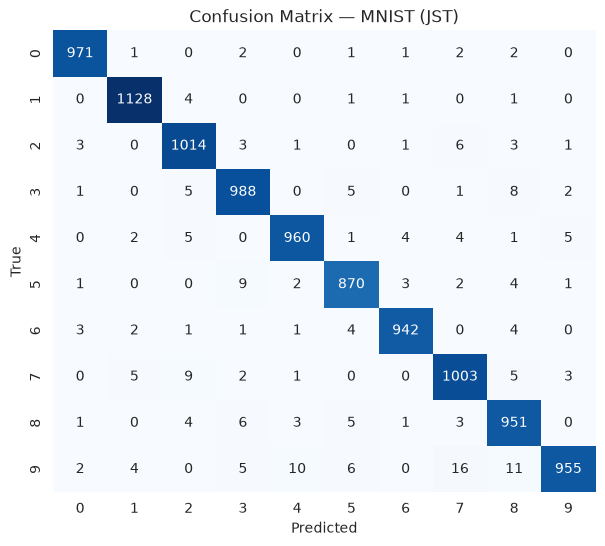

              precision    recall  f1-score   support

           0     0.9888    0.9908    0.9898       980
           1     0.9877    0.9938    0.9908      1135
           2     0.9731    0.9826    0.9778      1032
           3     0.9724    0.9782    0.9753      1010
           4     0.9816    0.9776    0.9796       982
           5     0.9742    0.9753    0.9748       892
           6     0.9885    0.9833    0.9859       958
           7     0.9672    0.9757    0.9714      1028
           8     0.9606    0.9764    0.9684       974
           9     0.9876    0.9465    0.9666      1009

    accuracy                         0.9782     10000
   macro avg     0.9782    0.9780    0.9780     10000
weighted avg     0.9783    0.9782    0.9782     10000



In [21]:
# Confusion matrix + classification report pada data uji MNIST
from sklearn.metrics import confusion_matrix, classification_report

y_pred_m = np.argmax(model_mnist.predict(X_test_m, verbose=0), axis=1)

plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_test_m, y_pred_m), annot=True, fmt='d',
            cmap='Blues', cbar=False)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion Matrix — MNIST (JST)')
plt.show()

print(classification_report(y_test_m, y_pred_m, digits=4))

In [22]:
# Eksperimen tambahan: variasi neuron, jumlah layer, dan fungsi aktivasi
def build_mnist(hidden, activation='relu'):
    m = models.Sequential([layers.Input(shape=(28, 28)), layers.Flatten()])
    for n in hidden:
        m.add(layers.Dense(n, activation=activation))
    m.add(layers.Dense(10, activation='softmax'))
    m.compile(optimizer='adam', loss='categorical_crossentropy',
              metrics=['accuracy'])
    return m

eksperimen = {
    '256-128 (baseline)': ([256, 128], 'relu'),
    '128-64 (lebih kecil)': ([128, 64], 'relu'),
    '512-256-128 (3 layer)': ([512, 256, 128], 'relu'),
    '256-128 (sigmoid)': ([256, 128], 'sigmoid'),
}

hasil_tugas = []
for nama, (hidden, act) in eksperimen.items():
    tf.random.set_seed(42)
    m = build_mnist(hidden, act)
    t0 = time.time()
    hh = m.fit(X_train_m, y_train_cat, epochs=5, batch_size=128,
               validation_split=0.1, verbose=0)
    durasi = time.time() - t0
    _, a = m.evaluate(X_test_m, y_test_cat, verbose=0)
    hasil_tugas.append({'Model': nama,
                        'Akurasi test': round(a, 4),
                        'Val accuracy terakhir': round(hh.history['val_accuracy'][-1], 4),
                        'Waktu 5 epoch (s)': round(durasi, 1)})

pd.DataFrame(hasil_tugas)

,Model,Akurasi test,Val accuracy terakhir,Waktu 5 epoch (s)
0,256-128 (baseline),0.9749,0.9765,9.8
1,128-64 (lebih kecil),0.9689,0.9738,6.9
2,512-256-128 (3 layer),0.9741,0.9727,18.3
3,256-128 (sigmoid),0.9632,0.9702,9.0


**Analisis Tugas Praktikum:**

- Model baseline **784 → 256 (ReLU) → 128 (ReLU) → 10 (Softmax)** mencapai akurasi test **≈0.97–0.98** dalam 10 epoch. Confusion matrix menunjukkan kesalahan tersebar tipis antar digit yang bentuknya mirip; kelas **1** punya recall tertinggi (≈0.99), sedangkan **9** paling sering tertukar (recall ≈0.95), disusul **5**, **7**, dan **8** (≈0.975).
- **Menambah hidden layer/neuron** (512-256-128) tidak menaikkan akurasi secara berarti (**≈0.97**) dan waktu training 5 epoch naik dari ±10 s menjadi ±18 s karena parameter bertambah. **Mengecilkan model** (128-64) memberi akurasi **≈0.97** dengan waktu training lebih singkat (±7 s) — untuk deployment, trade-off akurasi vs latency ini penting.
- **Sigmoid vs ReLU**: Sigmoid hanya mencapai **≈0.96** pada jumlah epoch yang sama karena gradiennya mengecil di layer awal (*vanishing gradient*), sementara ReLU konvergen lebih cepat. Ini konsisten dengan teori dan hasil Praktikum 1.
- Dataset MNIST tergolong "mudah" karena digit selalu terpusat dan ternormalisasi. Performa setinggi ini tidak otomatis berlaku pada foto tulisan tangan di dunia nyata, yang memiliki variasi kemiringan, ketebalan, dan latar belakang. Waktu training absolut dapat berbeda antar mesin dan antar eksekusi karena penjadwalan thread CPU.